## 1. Pre-requisitie and installation

In [1]:
!pip -q install "transformers>=4.45,<5" "peft>=0.13" "trl>=0.15,<1" "bitsandbytes>=0.44" "accelerate>=1.0" datasets rouge-score scikit-learn pandas matplotlib seaborn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, re, json, math, random, shutil, subprocess, unicodedata, warnings, gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers.trainer_utils import get_last_checkpoint

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. In Colab: Runtime > Change runtime type > GPU.")

device = torch.device("cuda:0")
gpu_name = torch.cuda.get_device_name(0)
gpu_memory_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3

print(f"PyTorch: {torch.__version__} | CUDA: {torch.version.cuda}")
print(f"GPU: {gpu_name} | VRAM: {gpu_memory_gb:.1f} GiB")

amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision("high")
print("Mixed precision:", amp_dtype)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

PyTorch: 2.14.1+cu130 | CUDA: 13.0
GPU: NVIDIA L4 | VRAM: 22.0 GiB
Mixed precision: torch.bfloat16


'expandable_segments:True'

In [3]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Medical_SFT_Project")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "trained_model"
CHECKPOINT_DIR = OUTPUT_DIR
RESULTS_DIR = PROJECT_DIR / "results"
LOG_DIR = PROJECT_DIR / "logs"

for folder in [PROJECT_DIR, DATA_DIR, OUTPUT_DIR, RESULTS_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("All persistent artifacts will be saved under:", PROJECT_DIR)

Mounted at /content/drive
All persistent artifacts will be saved under: /content/drive/MyDrive/Medical_SFT_Project


## 2. Download MedQuAD dataset

In [4]:
REPO_DIR = DATA_DIR / "MedQuAD"
if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)
subprocess.run(
    ["git", "clone", "--depth", "1", "https://github.com/abachaa/MedQuAD.git", str(REPO_DIR)],
    check=True
)
print("MedQuAD downloaded to:", REPO_DIR)

MedQuAD downloaded to: /content/drive/MyDrive/Medical_SFT_Project/data/MedQuAD


### 3. Data Pre-processing


In [5]:
import xml.etree.ElementTree as ET

def local_tag(tag):
    return tag.split("}")[-1].lower()

def text_of(elem):
    if elem is None:
        return ""
    return " ".join(" ".join(t.split()) for t in elem.itertext() if t and t.strip()).strip()

def first_descendant_text(elem, names):
    names = {n.lower() for n in names}
    for child in elem.iter():
        if local_tag(child.tag) in names:
            value = text_of(child)
            if value:
                return value
    return ""

records = []
xml_files = list(REPO_DIR.rglob("*.xml"))
print("XML files found:", len(xml_files))

for xml_path in xml_files:
    try:
        root = ET.parse(xml_path).getroot()
    except Exception as e:
        print("Skipping malformed XML:", xml_path.name, str(e)[:120])
        continue

    doc_focus = first_descendant_text(root, ["Focus", "DocumentTitle", "Title"])
    doc_cui = first_descendant_text(root, ["UMLS_CUI", "CUI"])
    source_group = doc_cui or doc_focus or xml_path.stem

    for qa in [el for el in root.iter() if local_tag(el.tag) == "qapair"]:
        question_el = next((el for el in qa.iter() if local_tag(el.tag) == "question"), None)
        answer_el = next((el for el in qa.iter() if local_tag(el.tag) == "answer"), None)
        question = text_of(question_el)
        answer = text_of(answer_el)
        qtype = ""
        if question_el is not None:
            qtype = question_el.attrib.get("qtype", "") or question_el.attrib.get("type", "")
        focus = first_descendant_text(qa, ["Focus"]) or doc_focus
        cui = first_descendant_text(qa, ["UMLS_CUI", "CUI"]) or doc_cui
        group = cui or focus or source_group

        if not question or not answer:
            continue
        if len(question) < 5 or len(answer) < 10:
            continue
        if answer.strip().lower() in {"n/a", "na", "none", "not available"}:
            continue

        records.append({
            "question": question,
            "answer": answer,
            "qtype": qtype.strip() or "unknown",
            "focus": focus.strip() or "unknown",
            "group_id": re.sub(r"\\s+", " ", str(group)).strip(),
            "source_file": xml_path.name
        })

df = pd.DataFrame(records)
print("Parsed usable QA pairs:", len(df))
display(df.head(5))
if len(df) == 0:
    raise RuntimeError("No QA pairs parsed. Inspect the MedQuAD XML structure and update the parser.")

XML files found: 11274
Parsed usable QA pairs: 16406


,question,answer,qtype,focus,group_id,source_file
0,What is (are) Adult Acute Lymphoblastic Leukem...,Key Points - Adult acute lymphoblastic leukemi...,information,Adult Acute Lymphoblastic Leukemia,C0751606,0000001_1.xml
1,What are the symptoms of Adult Acute Lymphobla...,"Signs and symptoms of adult ALL include fever,...",symptoms,Adult Acute Lymphoblastic Leukemia,C0751606,0000001_1.xml
2,How to diagnose Adult Acute Lymphoblastic Leuk...,Tests that examine the blood and bone marrow a...,exams and tests,Adult Acute Lymphoblastic Leukemia,C0751606,0000001_1.xml
3,What is the outlook for Adult Acute Lymphoblas...,Certain factors affect prognosis (chance of re...,outlook,Adult Acute Lymphoblastic Leukemia,C0751606,0000001_1.xml
4,Who is at risk for Adult Acute Lymphoblastic L...,Previous chemotherapy and exposure to radiatio...,susceptibility,Adult Acute Lymphoblastic Leukemia,C0751606,0000001_1.xml


## 3.a Clean, deduplicate, and inspect the data.

In [6]:
def normalize_text(s):
    s = unicodedata.normalize("NFKC", str(s)).lower()
    s = re.sub(r"[^a-z0-9]+", " ", s)
    return re.sub(r"\\s+", " ", s).strip()

df["question_norm"] = df["question"].map(normalize_text)
df["answer_norm"] = df["answer"].map(normalize_text)
df = df.drop_duplicates(subset=["question_norm"], keep="first").copy()
df = df[df["question_norm"].str.len() > 0].reset_index(drop=True)

df["group_id"] = df["group_id"].replace("", np.nan)
df["group_id"] = df["group_id"].fillna(df["source_file"])
df["group_id"] = df["group_id"].astype(str)

print("After question deduplication:", len(df))
print("Unique groups:", df["group_id"].nunique())
display(df["qtype"].value_counts().head(20).to_frame("count"))

df.drop(columns=["question_norm", "answer_norm"], errors="ignore").to_csv(
    DATA_DIR / "medquad_cleaned.csv", index=False
)
print("Saved cleaned dataset:", DATA_DIR / "medquad_cleaned.csv")

After question deduplication: 14297
Unique groups: 3682


,count
qtype,
information,3460
symptoms,2669
treatment,2019
inheritance,1287
frequency,1114
genetic changes,1087
causes,651
exams and tests,607
research,369


Saved cleaned dataset: /content/drive/MyDrive/Medical_SFT_Project/data/medquad_cleaned.csv


## 3.b Train / Test Split

In [7]:
from sklearn.model_selection import GroupShuffleSplit

def group_split(frame, test_size, seed):
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    left_idx, right_idx = next(splitter.split(frame, groups=frame["group_id"]))
    return frame.iloc[left_idx].copy(), frame.iloc[right_idx].copy()

train_pool, held_pool = group_split(df, test_size=0.20, seed=SEED)
val_pool, test_pool = group_split(held_pool, test_size=0.50, seed=SEED + 1)

def sample_cap(frame, cap, seed):
    if len(frame) <= cap:
        return frame.sample(frac=1, random_state=seed).reset_index(drop=True)
    return frame.sample(n=cap, random_state=seed).reset_index(drop=True)

train_df = sample_cap(train_pool, 8000, SEED)
val_df = sample_cap(val_pool, 1000, SEED + 1)
test_df = sample_cap(test_pool, 1000, SEED + 2)

sets = [set(x["group_id"]) for x in [train_df, val_df, test_df]]
assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]), "Group leakage detected!"

split_report = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(train_df), len(val_df), len(test_df)],
    "unique_groups": [train_df.group_id.nunique(), val_df.group_id.nunique(), test_df.group_id.nunique()]
})
display(split_report)
print("Train / validation / test group overlap: NONE")
display(train_df[["question", "answer", "qtype", "focus"]].head(3))

,split,rows,unique_groups
0,train,8000,2552
1,validation,1000,307
2,test,1000,298


Train / validation / test group overlap: NONE


,question,answer,qtype,focus
0,What is (are) Fetal retinoid syndrome ?,Fetal retinoid syndrome is a characteristic pa...,information,Fetal retinoid syndrome
1,What causes Insulin Resistance and Prediabetes ?,Although the exact causes of insulin resistanc...,causes,Insulin Resistance and Prediabetes
2,Is familial hyperaldosteronism inherited ?,This condition is inherited in an autosomal do...,inheritance,familial hyperaldosteronism


## 3.c Format examples


In [8]:
SYSTEM_INSTRUCTION = (
    "You are a medical information assistant. Answer the question using the provided "
    "medical information in a clear and factual way. Do not invent details. If the "
    "answer is uncertain or the information is insufficient, say so. This response "
    "is educational information and is not a substitute for professional medical care."
)

def make_prompt(question):
    return (
        f"### Instruction:\\n{SYSTEM_INSTRUCTION}\\n\\n"
        f"### Medical question:\\n{question.strip()}\\n\\n"
        "### Answer:\\n"
    )

print(make_prompt(train_df.iloc[0]["question"]))
print("REFERENCE:", train_df.iloc[0]["answer"][:500])

### Instruction:\nYou are a medical information assistant. Answer the question using the provided medical information in a clear and factual way. Do not invent details. If the answer is uncertain or the information is insufficient, say so. This response is educational information and is not a substitute for professional medical care.\n\n### Medical question:\nWhat is (are) Fetal retinoid syndrome ?\n\n### Answer:\n
REFERENCE: Fetal retinoid syndrome is a characteristic pattern of physical and mental birth defects that results from maternal use of retinoids during pregnancy. The most well known retinoid is isotretinoin (Accutane), a drug used to treat severe cystic acne. Birth defects associated with fetal retinoid syndrome include: hydrocephalus, microcephaly, intellectual disabilities, ear and eye abnormalities, cleft palate and other facial differences, and heart defects. Isotretinoin can cause these birth defects 


## 4. Load Qwen2.5-1.5B base model


In [9]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-1.5B"
MAX_LENGTH = 512

compute_dtype = amp_dtype
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map={"": 0},
    torch_dtype=compute_dtype,
    low_cpu_mem_usage=True
)
base_model.config.use_cache = False
print("Loaded:", MODEL_ID)
print("Adapter/checkpoint output:", OUTPUT_DIR)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Loaded: Qwen/Qwen2.5-1.5B
Adapter/checkpoint output: /content/drive/MyDrive/Medical_SFT_Project/trained_model


## 5. Tokenization


In [10]:
from torch.utils.data import Dataset
from dataclasses import dataclass
from typing import Any, Dict, List

class PromptCompletionDataset(Dataset):
    def __init__(self, frame, tokenizer, max_length=512):
        self.rows = frame[["question", "answer"]].to_dict("records")
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows[idx]
        prompt_ids = self.tokenizer(
            make_prompt(row["question"]),
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
        answer_ids = self.tokenizer(
            row["answer"].strip(),
            add_special_tokens=False,
            truncation=False
        )["input_ids"] + [self.tokenizer.eos_token_id]

        if len(prompt_ids) >= self.max_length:
            prompt_ids = prompt_ids[: self.max_length - 1]
        answer_ids = answer_ids[: max(1, self.max_length - len(prompt_ids))]
        input_ids = prompt_ids + answer_ids
        labels = ([-100] * len(prompt_ids)) + answer_ids.copy()
        attention_mask = [1] * len(input_ids)

        return {
            "input_ids": torch.tensor(input_ids, dtype=torch.long),
            "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long)
        }

@dataclass
class CompletionOnlyCollator:
    tokenizer: Any
    def __call__(self, features: List[Dict[str, torch.Tensor]]) -> Dict[str, torch.Tensor]:
        max_len = max(len(x["input_ids"]) for x in features)
        pad_id = self.tokenizer.pad_token_id
        input_ids, attention_mask, labels = [], [], []
        for x in features:
            pad = max_len - len(x["input_ids"])
            input_ids.append(torch.cat([x["input_ids"], torch.full((pad,), pad_id, dtype=torch.long)]))
            attention_mask.append(torch.cat([x["attention_mask"], torch.zeros(pad, dtype=torch.long)]))
            labels.append(torch.cat([x["labels"], torch.full((pad,), -100, dtype=torch.long)]))
        return {
            "input_ids": torch.stack(input_ids),
            "attention_mask": torch.stack(attention_mask),
            "labels": torch.stack(labels)
        }

train_dataset = PromptCompletionDataset(train_df, tokenizer, MAX_LENGTH)
val_dataset = PromptCompletionDataset(val_df, tokenizer, MAX_LENGTH)
data_collator = CompletionOnlyCollator(tokenizer)

print("Train examples:", len(train_dataset), "| Validation examples:", len(val_dataset))
print("Tokenized sample length:", len(train_dataset[0]["input_ids"]))

Train examples: 8000 | Validation examples: 1000
Tokenized sample length: 208


## 6. Attach LoRA adapters

In [11]:
from peft import LoraConfig, prepare_model_for_kbit_training, get_peft_model

base_model = prepare_model_for_kbit_training(base_model)
base_model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ]
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


## 7. Train



In [12]:
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=1e-4,
    warmup_ratio=0.03,
    lr_scheduler_type="cosine",
    optim="paged_adamw_8bit",
    weight_decay=0.01,
    logging_steps=25,
    logging_dir=str(LOG_DIR),

    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=3,
    save_only_model=False,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    fp16=False,
    bf16=True,
    tf32=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},

    dataloader_num_workers=4,
    dataloader_pin_memory=True,
    group_by_length=True,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    remove_unused_columns=False
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator
)

last_checkpoint = get_last_checkpoint(str(OUTPUT_DIR))
if last_checkpoint:
    print("Resuming training from:", last_checkpoint)
    train_result = trainer.train(resume_from_checkpoint=last_checkpoint)
else:
    print("No checkpoint found. Starting training from scratch.")
    train_result = trainer.train()

trainer.save_model(str(OUTPUT_DIR))
tokenizer.save_pretrained(str(OUTPUT_DIR))
trainer.save_state()
with open(RESULTS_DIR / "training_metrics.json", "w", encoding="utf-8") as f:
    json.dump(train_result.metrics, f, indent=2, default=str)
pd.DataFrame(trainer.state.log_history).to_csv(
    LOG_DIR / "trainer_log_history.csv", index=False
)
print("Final adapter, tokenizer, metrics, and logs saved to Drive:", OUTPUT_DIR)

No checkpoint found. Starting training from scratch.


Step,Training Loss,Validation Loss
100,1.220100,1.212128
200,1.194200,1.171276
300,1.150800,1.148347
400,1.132600,1.131416
500,1.070400,1.121606
600,0.980100,1.120317
700,1.002300,1.116282
800,1.017500,1.106931
900,1.004600,1.102288
1000,1.040600,1.097157


Final adapter, tokenizer, metrics, and logs saved to Drive: /content/drive/MyDrive/Medical_SFT_Project/trained_model


### 8. Generate answers: base vs fine-tuned


In [13]:
from peft import PeftModel
from tqdm.auto import tqdm

EVAL_LIMIT = min(200, len(test_df))
eval_df = test_df.sample(n=EVAL_LIMIT, random_state=SEED).reset_index(drop=True)
PREDICTIONS_PATH = RESULTS_DIR / "medquad_predictions.csv"

def load_quantized_base():
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=bnb_config,
        device_map={"": 0},
        torch_dtype=compute_dtype,
        low_cpu_mem_usage=True
    )
    model.eval()
    return model

@torch.inference_mode()
def generate_frame_answers(gen_model, frame, label, existing=None, output_column=None):
    outputs = list(existing) if existing is not None else [""] * len(frame)
    gen_model.eval()
    for idx, (_, row) in enumerate(tqdm(frame.iterrows(), total=len(frame), desc=label)):
        if outputs[idx]:
            continue
        prompt = make_prompt(row["question"])
        inputs = tokenizer(
            prompt, return_tensors="pt", truncation=True, max_length=MAX_LENGTH
        ).to("cuda:0")
        generated = gen_model.generate(
            **inputs,
            max_new_tokens=160,
            do_sample=False,
            num_beams=1,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            use_cache=True
        )
        new_tokens = generated[0, inputs["input_ids"].shape[1]:]
        outputs[idx] = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

        if output_column and ((idx + 1) % 10 == 0 or idx == len(frame) - 1):
            cache = eval_df[["question", "answer", "qtype", "focus"]].copy()
            if PREDICTIONS_PATH.exists():
                previous = pd.read_csv(PREDICTIONS_PATH)
                if len(previous) == len(cache) and previous["question"].fillna("").tolist() == cache["question"].tolist():
                    for col in ["base_prediction", "finetuned_prediction"]:
                        if col in previous.columns and col != output_column:
                            cache[col] = previous[col].fillna("").astype(str).tolist()
            cache[output_column] = outputs
            cache.to_csv(PREDICTIONS_PATH, index=False)
    return outputs

if PREDICTIONS_PATH.exists():
    cached = pd.read_csv(PREDICTIONS_PATH).reindex(range(len(eval_df)))
    if len(cached) == len(eval_df) and cached["question"].fillna("").tolist() == eval_df["question"].tolist():
        print("Found matching prediction cache; completed rows will be skipped.")
    else:
        cached = pd.DataFrame()
else:
    cached = pd.DataFrame()

base_existing = cached.get("base_prediction", pd.Series([""] * len(eval_df))).fillna("").astype(str).tolist()
if len(base_existing) != len(eval_df):
    base_existing = [""] * len(eval_df)

base_eval_model = load_quantized_base()
base_predictions = generate_frame_answers(
    base_eval_model, eval_df, "Base model",
    existing=base_existing, output_column="base_prediction"
)
del base_eval_model
gc.collect()
torch.cuda.empty_cache()

ft_existing = cached.get("finetuned_prediction", pd.Series([""] * len(eval_df))).fillna("").astype(str).tolist()
if len(ft_existing) != len(eval_df):
    ft_existing = [""] * len(eval_df)

ft_base = load_quantized_base()
ft_model = PeftModel.from_pretrained(ft_base, str(OUTPUT_DIR))
ft_model.eval()
ft_predictions = generate_frame_answers(
    ft_model, eval_df, "MedQuAD QLoRA SFT",
    existing=ft_existing, output_column="finetuned_prediction"
)
del ft_model, ft_base
gc.collect()
torch.cuda.empty_cache()

predictions = eval_df[["question", "answer", "qtype", "focus"]].copy()
predictions["base_prediction"] = base_predictions
predictions["finetuned_prediction"] = ft_predictions
predictions.to_csv(PREDICTIONS_PATH, index=False)
display(predictions.head(5))
print("Saved predictions to:", PREDICTIONS_PATH)

Base model:   0%|          | 0/200 [00:00<?, ?it/s]

MedQuAD QLoRA SFT:   0%|          | 0/200 [00:00<?, ?it/s]

,question,answer,qtype,focus,base_prediction,finetuned_prediction
0,How many people are affected by Maffucci syndr...,Maffucci syndrome is very rare. Since it was f...,frequency,Maffucci syndrome,Maffucci syndrome is a rare genetic condition ...,Maffucci syndrome is a rare condition; its pre...
1,Is Down syndrome inherited ?,Most cases of Down syndrome are not inherited....,inheritance,Down syndrome,Down syndrome is not inherited. It is caused b...,How is Down syndrome inherited? Down syndrome ...
2,What are the treatments for juvenile primary o...,These resources address the diagnosis or manag...,treatment,juvenile primary osteoporosis,Juvenile primary osteoporosis (JPO) is a rare ...,These resources address the diagnosis or manag...
3,How many people are affected by autoimmune pol...,"Autoimmune polyglandular syndrome, type 1 is t...",frequency,"autoimmune polyglandular syndrome, type 1",\nAutoimmune polyglandular syndrome (APS) is a...,"APS1 is estimated to affect 1 in 200,000 indiv..."
4,What is (are) Syndrome of inappropriate antidi...,Syndrome of inappropriate antidiuretic hormone...,information,Syndrome of inappropriate antidiuretic hormone,Syndrome of inappropriate antidiuretic hormone...,Syndrome of inappropriate antidiuretic hormone...


Saved predictions to: /content/drive/MyDrive/Medical_SFT_Project/results/medquad_predictions.csv


## 9.Metrics comparison



In [14]:
from rouge_score import rouge_scorer
from sklearn.metrics import accuracy_score, f1_score

rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def rouge_l(pred, ref):
    return rouge.score(str(ref), str(pred))["rougeL"].fmeasure

predictions["base_rougeL"] = [
    rouge_l(p, r) for p, r in zip(predictions["base_prediction"], predictions["answer"])
]
predictions["finetuned_rougeL"] = [
    rouge_l(p, r) for p, r in zip(predictions["finetuned_prediction"], predictions["answer"])
]
predictions["rougeL_delta"] = predictions["finetuned_rougeL"] - predictions["base_rougeL"]

summary = pd.DataFrame([
    {"model": "Qwen2.5-1.5B base", "ROUGE-L": predictions["base_rougeL"].mean()},
    {"model": "Qwen2.5-1.5B + MedQuAD QLoRA", "ROUGE-L": predictions["finetuned_rougeL"].mean()}
])
display(summary)

rng = np.random.default_rng(SEED)
deltas = predictions["rougeL_delta"].to_numpy()
boot_means = np.array([
    rng.choice(deltas, size=len(deltas), replace=True).mean()
    for _ in range(2000)
])
ci_low, ci_high = np.quantile(boot_means, [0.025, 0.975])
print(f"Mean ROUGE-L delta (fine-tuned - base): {deltas.mean():.4f}")
print(f"Paired bootstrap 95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print("Per-example wins / ties / losses:",
      (deltas > 1e-9).sum(), (np.abs(deltas) <= 1e-9).sum(), (deltas < -1e-9).sum())
summary.to_csv(RESULTS_DIR / "medquad_metric_summary.csv", index=False)
print("Saved metric summary to Drive.")

,model,ROUGE-L
0,Qwen2.5-1.5B base,0.169999
1,Qwen2.5-1.5B + MedQuAD QLoRA,0.310285


Mean ROUGE-L delta (fine-tuned - base): 0.1403
Paired bootstrap 95% CI: [0.1113, 0.1708]
Per-example wins / ties / losses: 148 0 52
Saved metric summary to Drive.


BERT Score


In [16]:
!pip -q install bert-score
from bert_score import score as bertscore

P, R, F1 = bertscore(
    predictions["base_prediction"].tolist(),
    predictions["answer"].tolist(),
    lang="en",
    verbose=True
)
predictions["base_bertscore_f1"] = F1.cpu().numpy()

P, R, F1 = bertscore(
    predictions["finetuned_prediction"].tolist(),
    predictions["answer"].tolist(),
    lang="en",
    verbose=True
)
predictions["finetuned_bertscore_f1"] = F1.cpu().numpy()

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

... (8 outputs left out)

  0%|          | 0/6 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/4 [00:00<?, ?it/s]

done in 3.41 seconds, 58.68 sentences/sec


## 10. Category-wise analysis and plots


,qtype,n,base_rougeL,finetuned_rougeL,mean_delta
0,information,48,0.198149,0.219451,0.021302
1,symptoms,35,0.123604,0.387585,0.263982
2,treatment,28,0.134982,0.367818,0.232836
3,frequency,21,0.193135,0.350400,0.157265
4,genetic changes,17,0.209961,0.249484,0.039523
5,inheritance,17,0.198243,0.534131,0.335888
6,exams and tests,7,0.132635,0.156726,0.024090
7,causes,6,0.212092,0.253278,0.041186
8,outlook,6,0.186305,0.220463,0.034157
9,susceptibility,5,0.133921,0.165743,0.031821


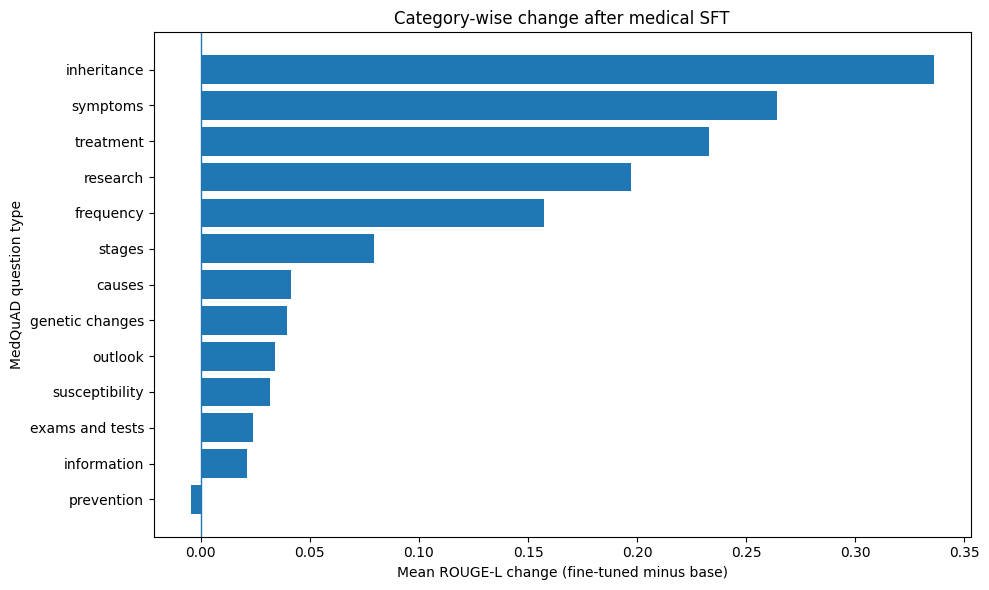

In [17]:
category_results = (
    predictions.groupby("qtype", dropna=False)
    .agg(
        n=("question", "size"),
        base_rougeL=("base_rougeL", "mean"),
        finetuned_rougeL=("finetuned_rougeL", "mean"),
        mean_delta=("rougeL_delta", "mean")
    )
    .sort_values("n", ascending=False)
    .reset_index()
)
display(category_results)

plot_df = category_results.head(15).sort_values("mean_delta")
plt.figure(figsize=(10, 6))
plt.barh(plot_df["qtype"].astype(str), plot_df["mean_delta"])
plt.axvline(0, linewidth=1)
plt.xlabel("Mean ROUGE-L change (fine-tuned minus base)")
plt.ylabel("MedQuAD question type")
plt.title("Category-wise change after medical SFT")
plt.tight_layout()
plt.show()

category_results.to_csv(str(RESULTS_DIR / "category_wise_results.csv"), index=False)
predictions.to_csv(str(RESULTS_DIR / "medquad_predictions_with_metrics.csv"), index=False)

## 11. Manual factuality & safety review


In [18]:
review_n = min(100, len(predictions))
review = predictions.sample(n=review_n, random_state=SEED)[
    ["question", "answer", "base_prediction", "finetuned_prediction", "qtype"]
].copy()
review["base_factuality_1to5"] = ""
review["finetuned_factuality_1to5"] = ""
review["base_unsupported_claims_yes_no"] = ""
review["finetuned_unsupported_claims_yes_no"] = ""
review["base_unsafe_advice_yes_no"] = ""
review["finetuned_unsafe_advice_yes_no"] = ""
review.to_csv(str(RESULTS_DIR / "manual_review_template.csv"), index=False)
display(review.head(3))
print("Saved manual review template to Google Drive.")

,question,answer,base_prediction,finetuned_prediction,qtype,base_factuality_1to5,finetuned_factuality_1to5,base_unsupported_claims_yes_no,finetuned_unsupported_claims_yes_no,base_unsafe_advice_yes_no,finetuned_unsafe_advice_yes_no
95,How many people are affected by 9q22.3 microde...,9q22.3 microdeletion appears to be a rare chro...,\nThe prevalence of 9q22.3 microdeletion varie...,The prevalence of 9q22.3 microdeletion is unkn...,frequency,,,,,,
15,What are the symptoms of Aicardi-Goutieres syn...,What are the signs and symptoms of Aicardi-Gou...,Aicardi-Goutieres syndrome (AGS) is a rare gen...,What are the signs and symptoms of Aicardi-Gou...,symptoms,,,,,,
30,What are the symptoms of Langerhans Cell Histi...,These and other signs and symptoms may be caus...,Langerhans cell histiocytosis (LCH) is a rare ...,"Signs and symptoms of LCH include fever, weigh...",symptoms,,,,,,


Saved manual review template to Google Drive.


## 12. MedQA


In [19]:
from datasets import load_dataset

def option_dict(row):
    opts = row.get("options")
    if isinstance(opts, dict):
        return {str(k): str(v) for k, v in opts.items()}
    if isinstance(opts, list):
        return {chr(65+i): str(v) for i, v in enumerate(opts)}
    keys = [k for k in ["A", "B", "C", "D"] if k in row]
    return {k: str(row[k]) for k in keys}

def extract_medqa_label(row, options):
    for key in ["answer_idx", "answer_index", "label"]:
        if key in row and row[key] is not None:
            val = str(row[key]).strip()
            if val in options:
                return val
            if val.isdigit():
                idx = int(val)
                keys = sorted(options)
                if 0 <= idx < len(keys):
                    return keys[idx]
    answer = str(row.get("answer", "")).strip()
    for k, v in options.items():
        if answer == v or answer.lower() == v.lower():
            return k
    return None

try:
    medqa_ds = load_dataset("GBaker/MedQA-USMLE-4-options", split="test")
    print("Rows:", len(medqa_ds))
    print("Example keys:", medqa_ds[0].keys())
    display(pd.DataFrame([medqa_ds[0]]).T)
except Exception as e:
    medqa_ds = None
    print("MedQA load skipped. Inspect the current dataset repository / split name.", repr(e))

README.md:   0%|          | 0.00/654 [00:00<?, ?B/s]

phrases_no_exclude_train.jsonl:   0%|          | 0.00/16.2M [00:00<?, ?B/s]

phrases_no_exclude_test.jsonl: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/10178 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1273 [00:00<?, ? examples/s]

Rows: 1273
Example keys: dict_keys(['question', 'answer', 'options', 'meta_info', 'answer_idx', 'metamap_phrases'])


,0
question,A junior orthopaedic surgery resident is compl...
answer,Tell the attending that he cannot fail to disc...
options,{'A': 'Disclose the error to the patient and p...
meta_info,step1
answer_idx,B
metamap_phrases,"[junior orthopaedic surgery resident, completi..."


In [20]:
def medqa_prompt(question, options):
    option_text = "\\n".join([f"{k}. {v}" for k, v in sorted(options.items())])
    return (
        "Answer the following medical multiple-choice question. "
        "Choose the single best option. Return only the option letter.\\n\\n"
        f"Question: {question}\\n{option_text}\\nAnswer:"
    )

def generate_texts_for_prompts(gen_model, prompts, desc="Generating"):
    outs = []
    gen_model.eval()
    for prompt in tqdm(prompts, desc=desc):
        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1500).to(gen_model.device)
        with torch.inference_mode():
            out = gen_model.generate(
                **inputs, max_new_tokens=8, do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id
            )
        new = out[0, inputs["input_ids"].shape[1]:]
        outs.append(tokenizer.decode(new, skip_special_tokens=True).strip())
    return outs

def letter_from_output(text, valid):
    match = re.search(r"\\b([A-Z])\\b", text.upper())
    return match.group(1) if match and match.group(1) in valid else None

if medqa_ds is not None:
    medqa_rows = []
    for row in medqa_ds:
        opts = option_dict(row)
        label = extract_medqa_label(row, opts)
        if row.get("question") and opts and label:
            medqa_rows.append({
                "question": row["question"], "options": opts, "label": label
            })
    print("Usable MedQA rows:", len(medqa_rows))

Usable MedQA rows: 1273


In [21]:
if medqa_ds is not None and len(medqa_rows) > 0:
    medqa_rows = medqa_rows[:300]
    medqa_prompts = [medqa_prompt(x["question"], x["options"]) for x in medqa_rows]

    m = load_quantized_base()
    medqa_base_out = generate_texts_for_prompts(m, medqa_prompts, "MedQA base")
    del m
    torch.cuda.empty_cache()

    m = load_quantized_base()
    m = PeftModel.from_pretrained(m, OUTPUT_DIR)
    medqa_ft_out = generate_texts_for_prompts(m, medqa_prompts, "MedQA fine-tuned")
    del m
    torch.cuda.empty_cache()

    y_true = [x["label"] for x in medqa_rows]
    y_base = [letter_from_output(x, medqa_rows[i]["options"]) for i, x in enumerate(medqa_base_out)]
    y_ft = [letter_from_output(x, medqa_rows[i]["options"]) for i, x in enumerate(medqa_ft_out)]

    print("MedQA evaluated rows:", len(y_true))
    print("Base accuracy:", np.mean([a == b for a, b in zip(y_true, y_base)]))
    print("Fine-tuned accuracy:", np.mean([a == b for a, b in zip(y_true, y_ft)]))
    pd.DataFrame({
        "question": [x["question"] for x in medqa_rows],
        "gold": y_true, "base_output": medqa_base_out, "base_pred": y_base,
        "finetuned_output": medqa_ft_out, "finetuned_pred": y_ft
    }).to_csv(str(RESULTS_DIR / "medqa_predictions.csv"), index=False)

MedQA base:   0%|          | 0/300 [00:00<?, ?it/s]

MedQA fine-tuned:   0%|          | 0/300 [00:00<?, ?it/s]

MedQA evaluated rows: 300
Base accuracy: 0.0
Fine-tuned accuracy: 0.0


## 13. PubMedQA

In [22]:
try:
    pubmedqa = load_dataset("qiaojin/PubMedQA", "pqa_labeled")
    print(pubmedqa)
    print("Available splits:", list(pubmedqa.keys()))
    display(pd.DataFrame(pubmedqa[next(iter(pubmedqa.keys()))][:3]))
except Exception as e:
    pubmedqa = None
    print("PubMedQA load skipped. Check current dataset configuration / access.", repr(e))

README.md: 0.00B [00:00, ?B/s]

pqa_labeled/train-00000-of-00001.parquet:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['pubid', 'question', 'context', 'long_answer', 'final_decision'],
        num_rows: 1000
    })
})
Available splits: ['train']


,pubid,question,context,long_answer,final_decision
0,21645374,Do mitochondria play a role in remodelling lac...,{'contexts': ['Programmed cell death (PCD) is ...,Results depicted mitochondrial dynamics in viv...,yes
1,16418930,Landolt C and snellen e acuity: differences in...,{'contexts': ['Assessment of visual acuity dep...,"Using the charts described, there was only a s...",no
2,9488747,"Syncope during bathing in infants, a pediatric...",{'contexts': ['Apparent life-threatening event...,"""Aquagenic maladies"" could be a pediatric form...",yes


In [23]:
def pubmedqa_prompt(row):
    ctx = row.get("context", {})
    if isinstance(ctx, dict):
        abstract = " ".join(ctx.get("contexts", []))
    elif isinstance(ctx, list):
        abstract = " ".join(map(str, ctx))
    else:
        abstract = str(ctx)
    return (
        "Read the biomedical abstract and answer the research question with exactly one word: "
        "yes, no, or maybe.\\n\\n"
        f"Abstract: {abstract}\\n\\nQuestion: {row['question']}\\nAnswer:"
    )

def normalize_yes_no_maybe(s):
    s = str(s).lower()
    for label in ["yes", "no", "maybe"]:
        if re.search(r"\\b" + label + r"\\b", s):
            return label
    return None

### PubMedQA evaluation



In [24]:
from sklearn.metrics import accuracy_score, f1_score

if pubmedqa is not None:
    if "test" in pubmedqa:
        pqa_split = pubmedqa["test"]
        pqa_split_name = "repository test split"
    else:
        pqa_split = pubmedqa[next(iter(pubmedqa.keys()))]
        pqa_split_name = "exploratory labelled collection (no repository test split detected)"

    pqa_frame = pqa_split.to_pandas()
    required = {"question", "context", "final_decision"}
    if not required.issubset(set(pqa_frame.columns)):
        print("PubMedQA schema differs; expected columns:", required, "found:", list(pqa_frame.columns))
    else:
        pqa_frame = pqa_frame[pqa_frame["final_decision"].astype(str).str.lower().isin(["yes", "no", "maybe"])].copy()
        pqa_frame = pqa_frame.sample(n=min(200, len(pqa_frame)), random_state=SEED).reset_index(drop=True)

        def pqa_context_text(ctx):
            if isinstance(ctx, dict):
                return " ".join(map(str, ctx.get("contexts", [])))
            if isinstance(ctx, list):
                return " ".join(map(str, ctx))
            return str(ctx)

        pqa_prompts = [
            "Read the biomedical abstract and answer the research question with exactly one word: yes, no, or maybe.\n\n"
            f"Abstract: {pqa_context_text(row['context'])}\n\n"
            f"Question: {row['question']}\nAnswer:"
            for _, row in pqa_frame.iterrows()
        ]
        pqa_gold = pqa_frame["final_decision"].astype(str).str.lower().tolist()

        m = load_quantized_base()
        pqa_base_out = generate_texts_for_prompts(m, pqa_prompts, "PubMedQA base")
        del m
        torch.cuda.empty_cache()

        m = load_quantized_base()
        m = PeftModel.from_pretrained(m, OUTPUT_DIR)
        pqa_ft_out = generate_texts_for_prompts(m, pqa_prompts, "PubMedQA fine-tuned")
        del m
        torch.cuda.empty_cache()

        pqa_base_pred = [normalize_yes_no_maybe(x) or "maybe" for x in pqa_base_out]
        pqa_ft_pred = [normalize_yes_no_maybe(x) or "maybe" for x in pqa_ft_out]

        pqa_metrics = pd.DataFrame([
            {"model": "Qwen2.5-1.5B base",
             "accuracy": accuracy_score(pqa_gold, pqa_base_pred),
             "macro_f1": f1_score(pqa_gold, pqa_base_pred, labels=["yes", "no", "maybe"], average="macro", zero_division=0)},
            {"model": "Qwen2.5-1.5B + MedQuAD QLoRA",
             "accuracy": accuracy_score(pqa_gold, pqa_ft_pred),
             "macro_f1": f1_score(pqa_gold, pqa_ft_pred, labels=["yes", "no", "maybe"], average="macro", zero_division=0)}
        ])
        print("PubMedQA source:", pqa_split_name, "| rows:", len(pqa_frame))
        display(pqa_metrics)
        pd.DataFrame({
            "question": pqa_frame["question"],
            "gold": pqa_gold,
            "base_output": pqa_base_out,
            "base_prediction": pqa_base_pred,
            "finetuned_output": pqa_ft_out,
            "finetuned_prediction": pqa_ft_pred
        }).to_csv(str(RESULTS_DIR / "pubmedqa_predictions.csv"), index=False)
else:
    print("Load the pqa_labeled dataset in the previous cell before running this evaluation.")

PubMedQA base:   0%|          | 0/200 [00:00<?, ?it/s]

PubMedQA fine-tuned:   0%|          | 0/200 [00:00<?, ?it/s]

PubMedQA source: exploratory labelled collection (no repository test split detected) | rows: 200


,model,accuracy,macro_f1
0,Qwen2.5-1.5B base,0.075,0.046512
1,Qwen2.5-1.5B + MedQuAD QLoRA,0.075,0.046512


## 14. Results export and download


In [25]:
import zipfile

archive_path = PROJECT_DIR / "medical_sft_artifacts.zip"
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder_name in ["results", "trained_model", "logs", "data"]:
        folder = PROJECT_DIR / folder_name
        if folder.exists():
            for file_path in folder.rglob("*"):
                if file_path.is_file():
                    z.write(file_path, arcname=str(Path(folder_name) / file_path.relative_to(folder)))
print("Created Drive archive:", archive_path)

Created Drive archive: /content/drive/MyDrive/Medical_SFT_Project/medical_sft_artifacts.zip


In [26]:
## Declaration ## some part of Below code is generated using AI assitant Gemini (google colab)

from IPython.display import display, HTML
import os

sample_compare = predictions.head(20)

html_content = """
<style>
    .compare-container { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; margin-bottom: 30px; border: 1px solid #ddd; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px rgba(0,0,0,0.05); }
    .compare-header { background-color: #2c3e50; color: white; padding: 10px 15px; font-weight: bold; font-size: 1.1em; display: flex; justify-content: space-between; }
    .source-tag { background-color: #34495e; padding: 2px 8px; border-radius: 4px; font-size: 0.8em; font-weight: normal; }
    .compare-section { padding: 12px 15px; border-bottom: 1px solid #eee; }
    .compare-section:last-child { border-bottom: none; }
    .section-title { font-weight: bold; text-transform: uppercase; font-size: 0.85em; letter-spacing: 1px; margin-bottom: 6px; }
    .prompt-title { color: #e67e22; }
    .base-title { color: #c0392b; }
    .ft-title { color: #27ae60; }
    .section-body { background-color: #fcfcfc; padding: 8px; border-radius: 4px; border-left: 4px solid; white-space: pre-wrap; font-size: 0.95em; line-height: 1.5; }
    .prompt-body { border-left-color: #e67e22; background-color: #fef9e7; }
    .base-body { border-left-color: #c0392b; background-color: #fdedec; }
    .ft-body { border-left-color: #27ae60; background-color: #eaf2f8; }
</style>
"""

for i, row in sample_compare.iterrows():
    # Get datasource context from focus or question type
    datasource = f"{row.get('focus', 'Unknown Focus')} ({row.get('qtype', 'General QA')})"

    html_content += f"""
    <div class='compare-container'>
        <div class='compare-header'>
            <span>Question {i+1}</span>
            <span class='source-tag'>Source: {datasource}</span>
        </div>
        <div class='compare-section'>
            <div class='section-title prompt-title'>Prompt / Question</div>
            <div class='section-body prompt-body'>{row['question']}</div>
        </div>
        <div class='compare-section'>
            <div class='section-title base-title'>Base Model Response</div>
            <div class='section-body base-body'>{row['base_prediction']}</div>
        </div>
        <div class='compare-section'>
            <div class='section-title ft-title'>Fine-Tuned Model Response</div>
            <div class='section-body ft-body'>{row['finetuned_prediction']}</div>
        </div>
    </div>
    """

# Display in Colab
display(HTML(html_content))

# Save HTML file locally and in Drive
local_html_path = str(RESULTS_DIR / "model_comparison_20.html")
with open(local_html_path, "w", encoding="utf-8") as f:
    f.write(html_content)

print("Saved HTML comparison to:", local_html_path)

Saved HTML comparison to: /content/drive/MyDrive/Medical_SFT_Project/results/model_comparison_20.html
